# R2 Logit-lens layer scan (E7) on Qwen2.5-3B: saved outputs

For five probe prompts, the same example is given in each of the three roles. At the first answer token where a copied answer and a non-copied answer differ, we read each layer's guess through the model's output head (the *logit lens*). `diff` = log-prob of the copied token minus the alternative: above 0 means the layer leans towards copying.

**What it shows.** The three roles start to separate around layers 23 to 28 of 36. **What it does not show.** This is a read-out, not a causal test. Causal tests (activation patching, ablation with random controls) are planned for the main study.

In [1]:
# Works locally (run from the repo) and in Colab (clones the public repo; no GPU needed).
import os, json, subprocess
if not os.path.exists('results/behaviour'):
    if not os.path.exists('/content/ContextLLM'):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/Tanjamul-Azad/ContextLLM.git', '/content/ContextLLM'], check=True)
    os.chdir('/content/ContextLLM')
import pandas as pd
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 200)
from IPython.display import Image, Markdown, display
print('reading saved results from', os.path.abspath('results'))

reading saved results from F:\UIU\13\Paper\ContextLLM\results


In [2]:
s = json.load(open('results/logit_lens/qwen2.5-3b/summary.json'))
rows = [{'probe': k, 'separation layer': v['separation_layer'], 'layers': v['n_layers'],
         **{f'final diff ({r})': v['final_diff'][r] for r in v['final_diff']},
         **{f'top token ({r})': v['final_top_token'][r] for r in v['final_top_token']},
         'role-correct at output': v['role_correct_at_output']} for k, v in s['probes'].items()]
display(pd.DataFrame(rows))

,probe,separation layer,layers,final diff (analogy),final diff (requirement),final diff (counter),top token (analogy),top token (requirement),top token (counter),role-correct at output
0,P1_helpdesk_triage,25,36,3.44,7.32,3.38,Red,Red,Red,False
1,P2_drone_pricing,28,36,-6.97,-3.36,-9.73,Flight,Flight,Initial,False
2,P6_exam_hall_boarding,23,36,-1.51,13.33,-6.03,Group,Zone,Group,True
3,C1_window_sum,25,36,-7.74,11.48,-6.04,):\n,=,):\n,True
4,C2_retry_backoff,28,36,0.25,5.00,1.25,1,1,1,False


In [3]:
scan = pd.read_csv('results/logit_lens/qwen2.5-3b/layer_scan.csv')
display(scan.pivot_table(index='layer', columns=['seed', 'role'], values='diff').round(2).tail(14))

seed  C1_window_sum                     C2_retry_backoff                     P1_helpdesk_triage                     P2_drone_pricing                     P6_exam_hall_boarding                    
role        analogy counter requirement          analogy counter requirement            analogy counter requirement          analogy counter requirement               analogy counter requirement
layer                                                                                                                                                                                             
23             0.03    0.14        0.52            -2.44   -2.71       -3.29              -3.94   -3.73       -3.76           -12.09  -10.99      -11.35                 -7.11   -7.42       -6.22
24            -2.80   -2.52       -1.84            -4.91   -5.31       -5.34              -3.51   -2.88       -1.91           -10.71   -9.86      -10.17                 -7.64   -8.31       -5.51
25            -2.24   -2.02       -0.33            -4.52   -4.58       -3.90              -5.47   -5.65       -3.39            -9.94   -9.86       -9.69                 -6.24   -6.72       -4.06
26            -1.53   -0.66        1.34            -4.48   -4.81       -3.49              -7.30   -7.00       -5.91           -11.78  -11.57      -11.27                 -6.73   -7.23       -3.29
27            -3.43   -2.38        1.01            -5.58   -6.36       -5.48              -8.19   -8.27       -5.32           -12.69  -12.11      -12.71                 -8.61   -8.68       -5.64
28            -2.65   -1.56        3.21            -5.70   -6.36       -3.92              -7.19   -7.72       -3.02           -12.96  -13.97      -12.42                -10.76  -11.08       -4.46
29            -6.19   -4.22        0.62            -6.50   -6.84       -4.45             -12.66  -11.56       -5.36           -13.98  -16.07      -12.27                -10.29  -10.18       -3.23
30            -7.25   -4.97        4.92            -4.67   -4.88       -2.54             -12.33  -11.63       -6.37           -13.14  -16.47      -11.81                 -9.74  -10.36       -4.61
31           -10.89   -8.90        4.90            -4.67   -4.64       -1.34             -12.91   -9.42       -3.46           -11.01  -13.61       -9.62                 -8.95   -9.87       -2.65
32           -11.94  -10.06        8.47            -7.25   -7.91       -0.94             -10.31   -9.16       -2.13           -11.88  -15.05       -9.66                 -9.00  -11.75        0.13
33           -14.19  -11.60        7.66            -4.81   -3.81        3.87              -8.31   -8.23        7.01           -10.16  -13.00       -9.49                 -5.78  -10.89        4.37
34           -11.16   -7.78       10.78            -1.69   -0.25        6.12               4.83    4.24        8.73           -10.18  -10.94       -6.12                 -1.25   -9.19       15.33
35            -5.82   -3.57        9.95             0.12    0.88        4.62               5.76    4.68        7.51            -7.60   -8.22       -4.34                 -1.64   -6.52        9.50
36            -7.74   -6.04       11.48             0.25    1.25        5.00               3.44    3.38        7.32            -6.97   -9.73       -3.36                 -1.51   -6.03       13.33

## Figures, one per probe

C1_window_sum.png


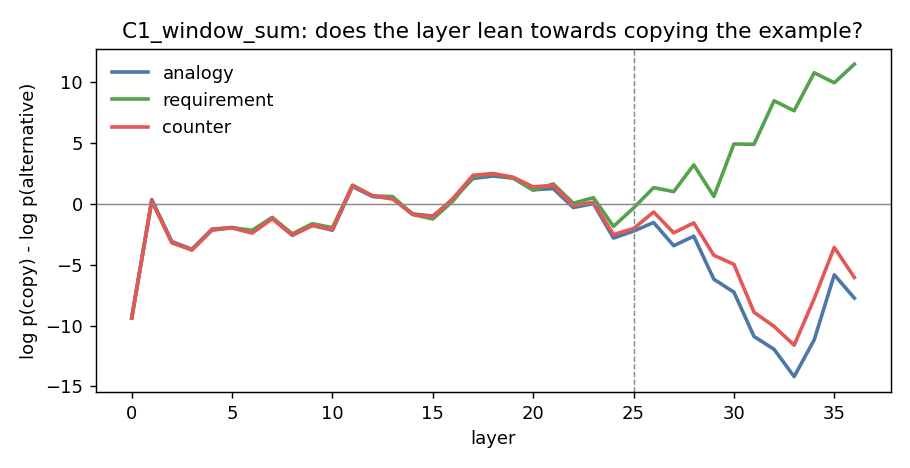

C2_retry_backoff.png


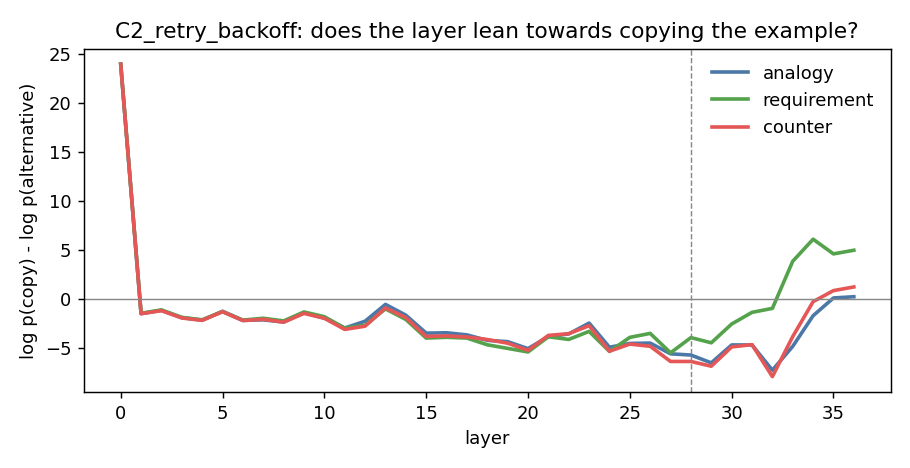

P1_helpdesk_triage.png


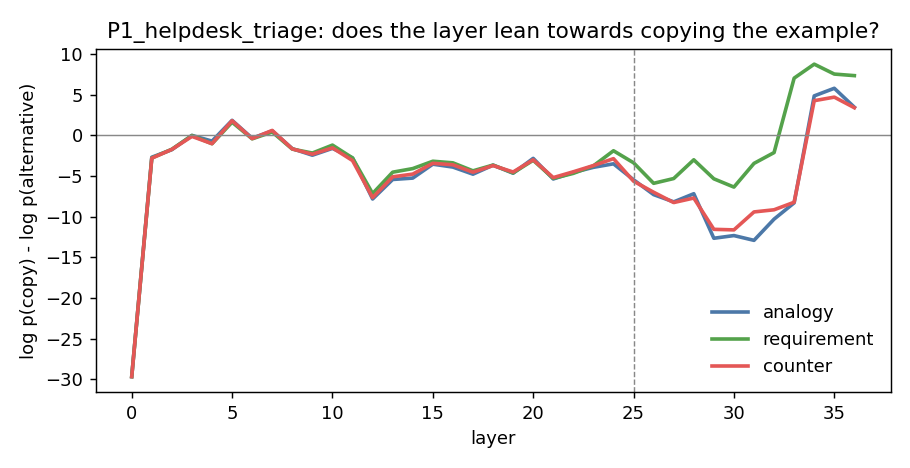

P2_drone_pricing.png


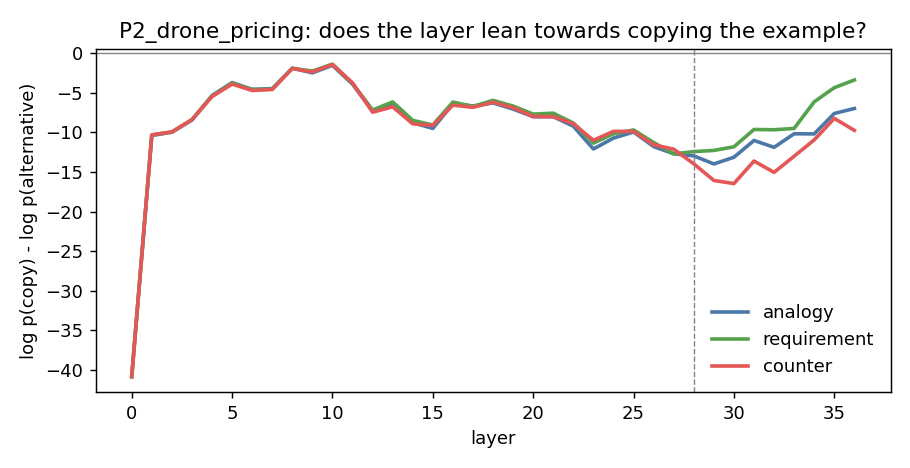

P6_exam_hall_boarding.png


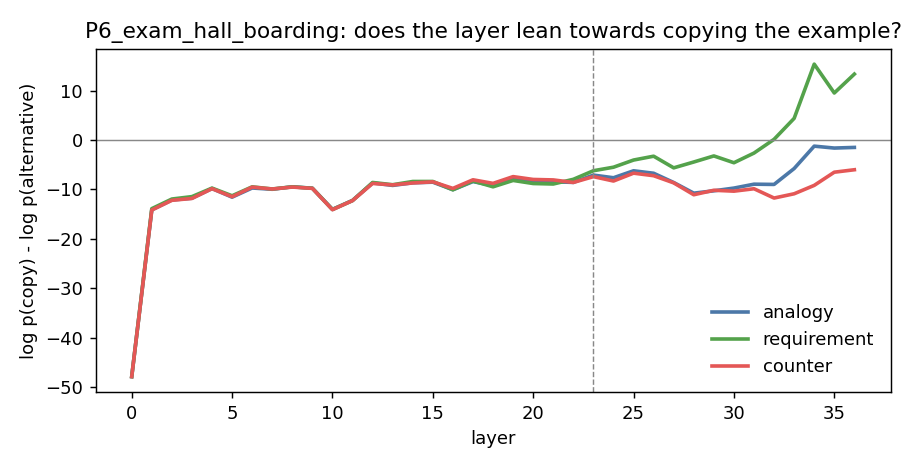

In [4]:
import glob
for p in sorted(glob.glob('results/logit_lens/qwen2.5-3b/*.png')):
    print(os.path.basename(p)); display(Image(p))

In [5]:
# Optional, Colab only: copy these saved outputs into Google Drive (DL paper/03_Results/logit_lens).
import shutil
try:
    from google.colab import drive
    drive.mount('/content/drive')
    for src in ['results/logit_lens']:
        dst = '/content/drive/MyDrive/DL paper/03_Results/logit_lens/' + os.path.basename(src.rstrip('/'))
        shutil.copytree(src, dst, dirs_exist_ok=True); print('copied', src, '->', dst)
except ImportError:
    print('Not in Colab: skipped. The files are in the repo under', ['results/logit_lens'])

Not in Colab: skipped. The files are in the repo under ['results/logit_lens']
